# Phase 9 — KUB U-Net Baseline Training

**Completed results notebook — display only.** This notebook reads saved Phase-9 assets. It does **not** import or invoke the training entrypoint and will not retrain on Restart/Run All.

- Experiment: `phase9_kub_unet_baseline_seed42_512`
- Manifest: `phase4_v2`
- Evaluation split: **VAL only** (n=283)
- Fixed threshold: 0.5
- TEST: locked and not evaluated
- External data: not used

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
EXP = ROOT / 'experiments/phase9_kub_unet_baseline_seed42_512'
TABLES = ROOT / 'reports/tables'
FIGURES = ROOT / 'reports/figures/phase9_unet_baseline'
QUAL = ROOT / 'reports/qualitative/phase9_unet_baseline'
summary = json.loads((EXP / 'summary.json').read_text(encoding='utf-8'))
assert summary['manifest_version'] == 'phase4_v2'
assert summary['test_accessed'] is False and summary['external_accessed'] is False
print('Display-only asset validation: PASS')

Display-only asset validation: PASS


## Frozen protocol and run outcome

In [2]:
protocol = pd.DataFrame([
 ['Model', 'Standard U-Net (1→1 channels, base=32; 7,762,465 parameters)'],
 ['Input', '512×512 aspect-ratio resize + symmetric padding'],
 ['Training', 'Seed 42; batch 4; AMP; AdamW (LR=1e-4, WD=1e-4)'],
 ['Objective', '0.5 BCEWithLogitsLoss + 0.5 DiceLoss'],
 ['Selection', 'VAL macro Dice; fixed threshold 0.5; patience 15'],
 ['Outcome', f"Epochs {summary['epochs_completed']}; best epoch {summary['best_epoch']}; early stopped={summary['early_stopped']}"],
], columns=['Item','Value'])
display(protocol)

,Item,Value
0,Model,"Standard U-Net (1→1 channels, base=32; 7,762,4..."
1,Input,512×512 aspect-ratio resize + symmetric padding
2,Training,"Seed 42; batch 4; AMP; AdamW (LR=1e-4, WD=1e-4)"
3,Objective,0.5 BCEWithLogitsLoss + 0.5 DiceLoss
4,Selection,VAL macro Dice; fixed threshold 0.5; patience 15
5,Outcome,Epochs 62; best epoch 47; early stopped=True


## Overall VAL metrics

In [3]:
display(pd.read_csv(TABLES / 'phase9_unet_val_summary.csv'))

,Metric_Type,N_Samples,Macro_Dice,Macro_IoU,Macro_Precision,Macro_Recall,Micro_Dice,Micro_IoU,Global_TP_Pixels,Global_FP_Pixels,Global_FN_Pixels,HD95_Valid_N,HD95_Invalid_N,Empty_Predictions_N,Empty_Prediction_Rate,Median_Valid_HD95,Mean_Valid_HD95
0,Macro_and_Micro,283,0.745544,0.631643,0.799446,0.765422,0.838204,0.721473,9241328,1782283,1785363,275,8,8,0.028269,40.380669,53.611312


## Training curves

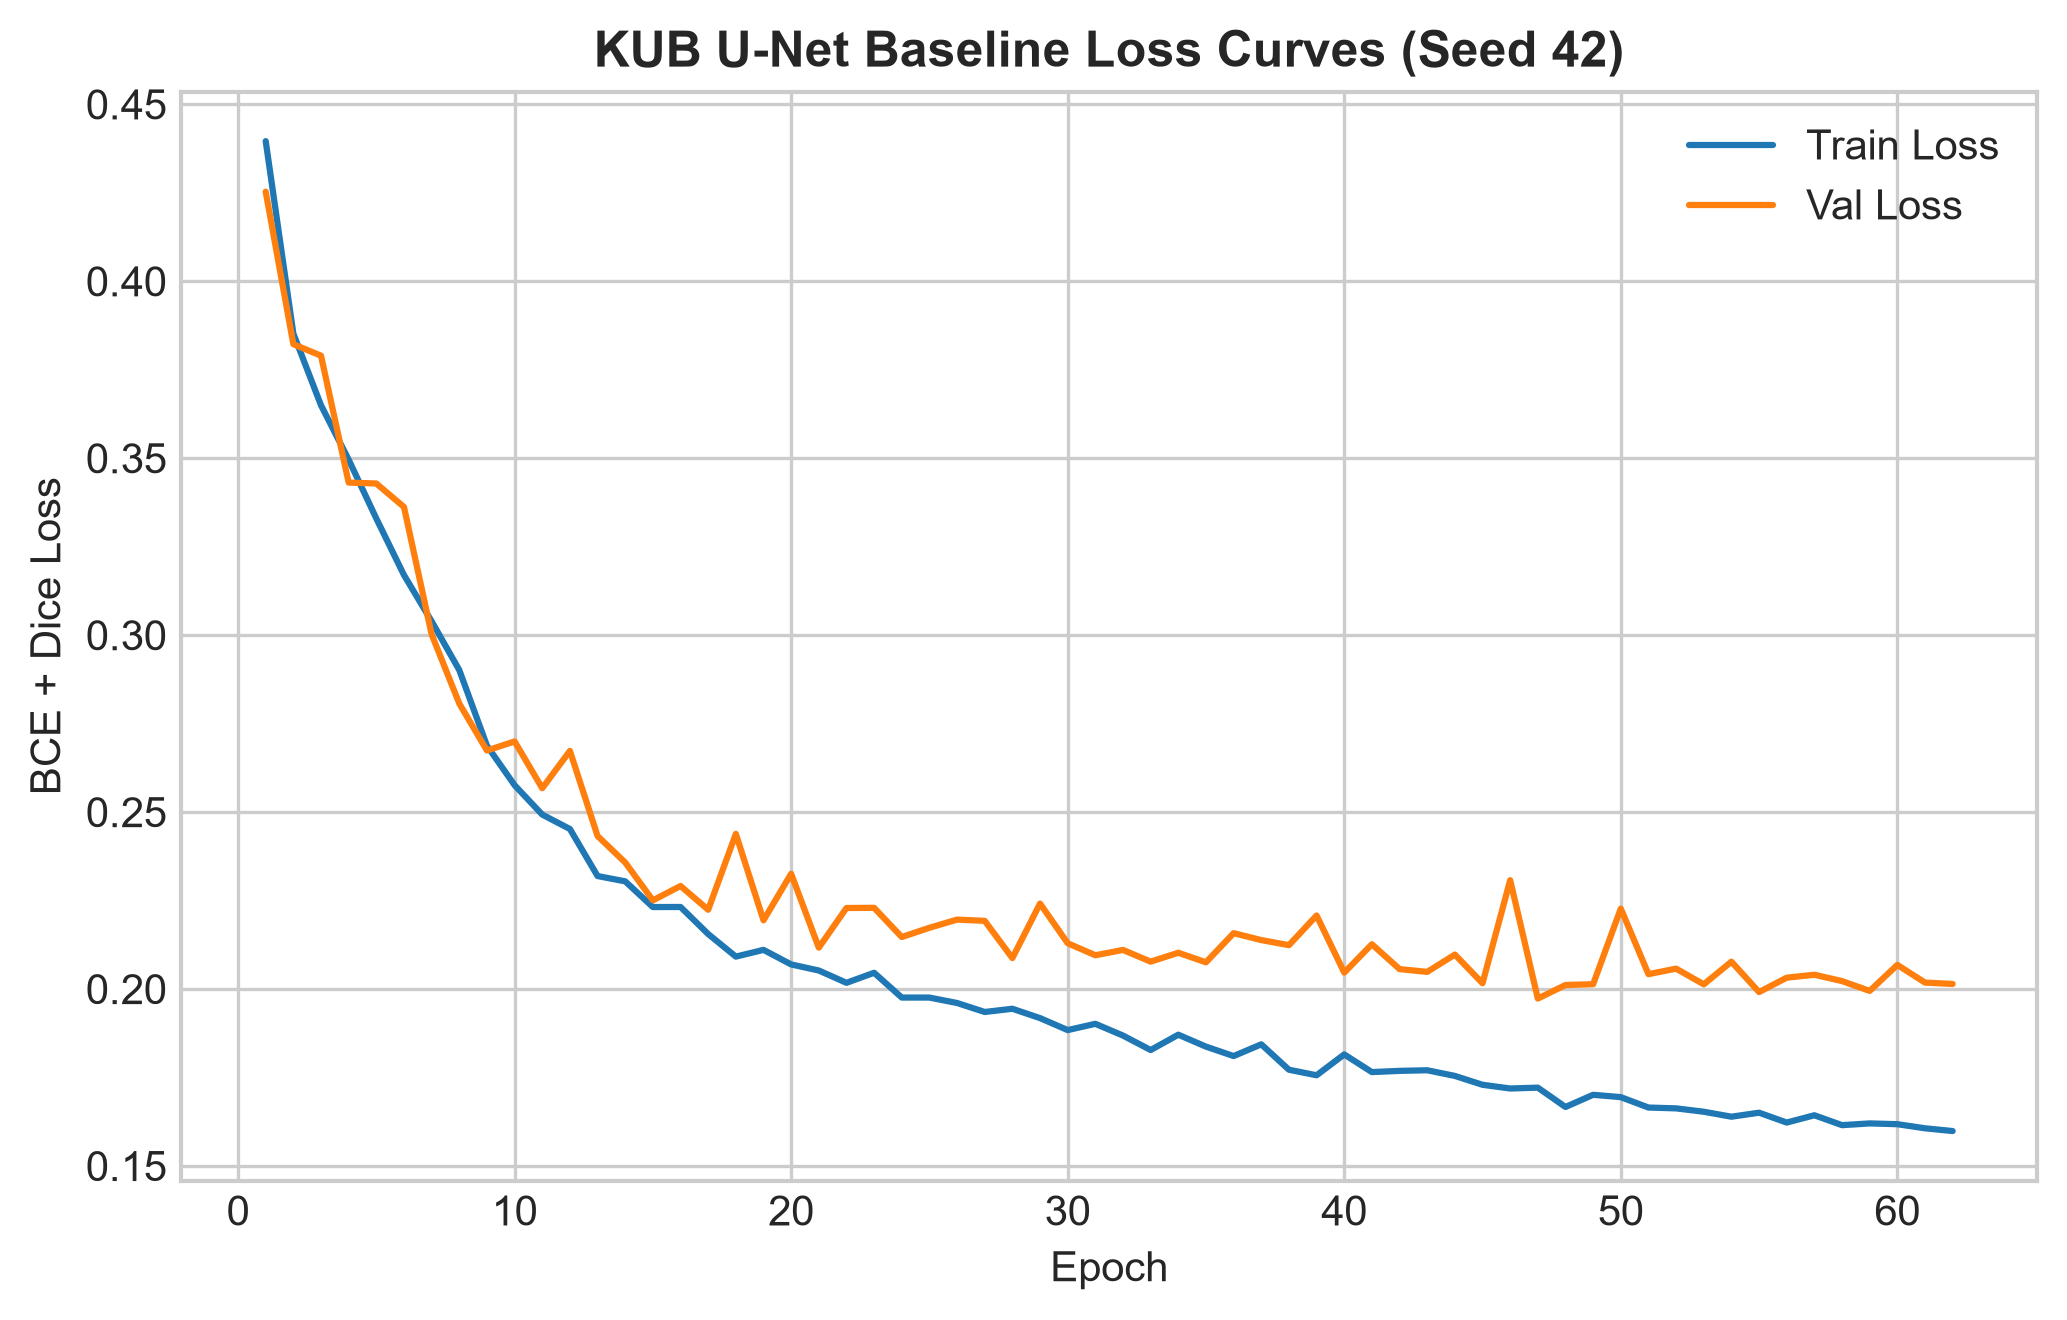

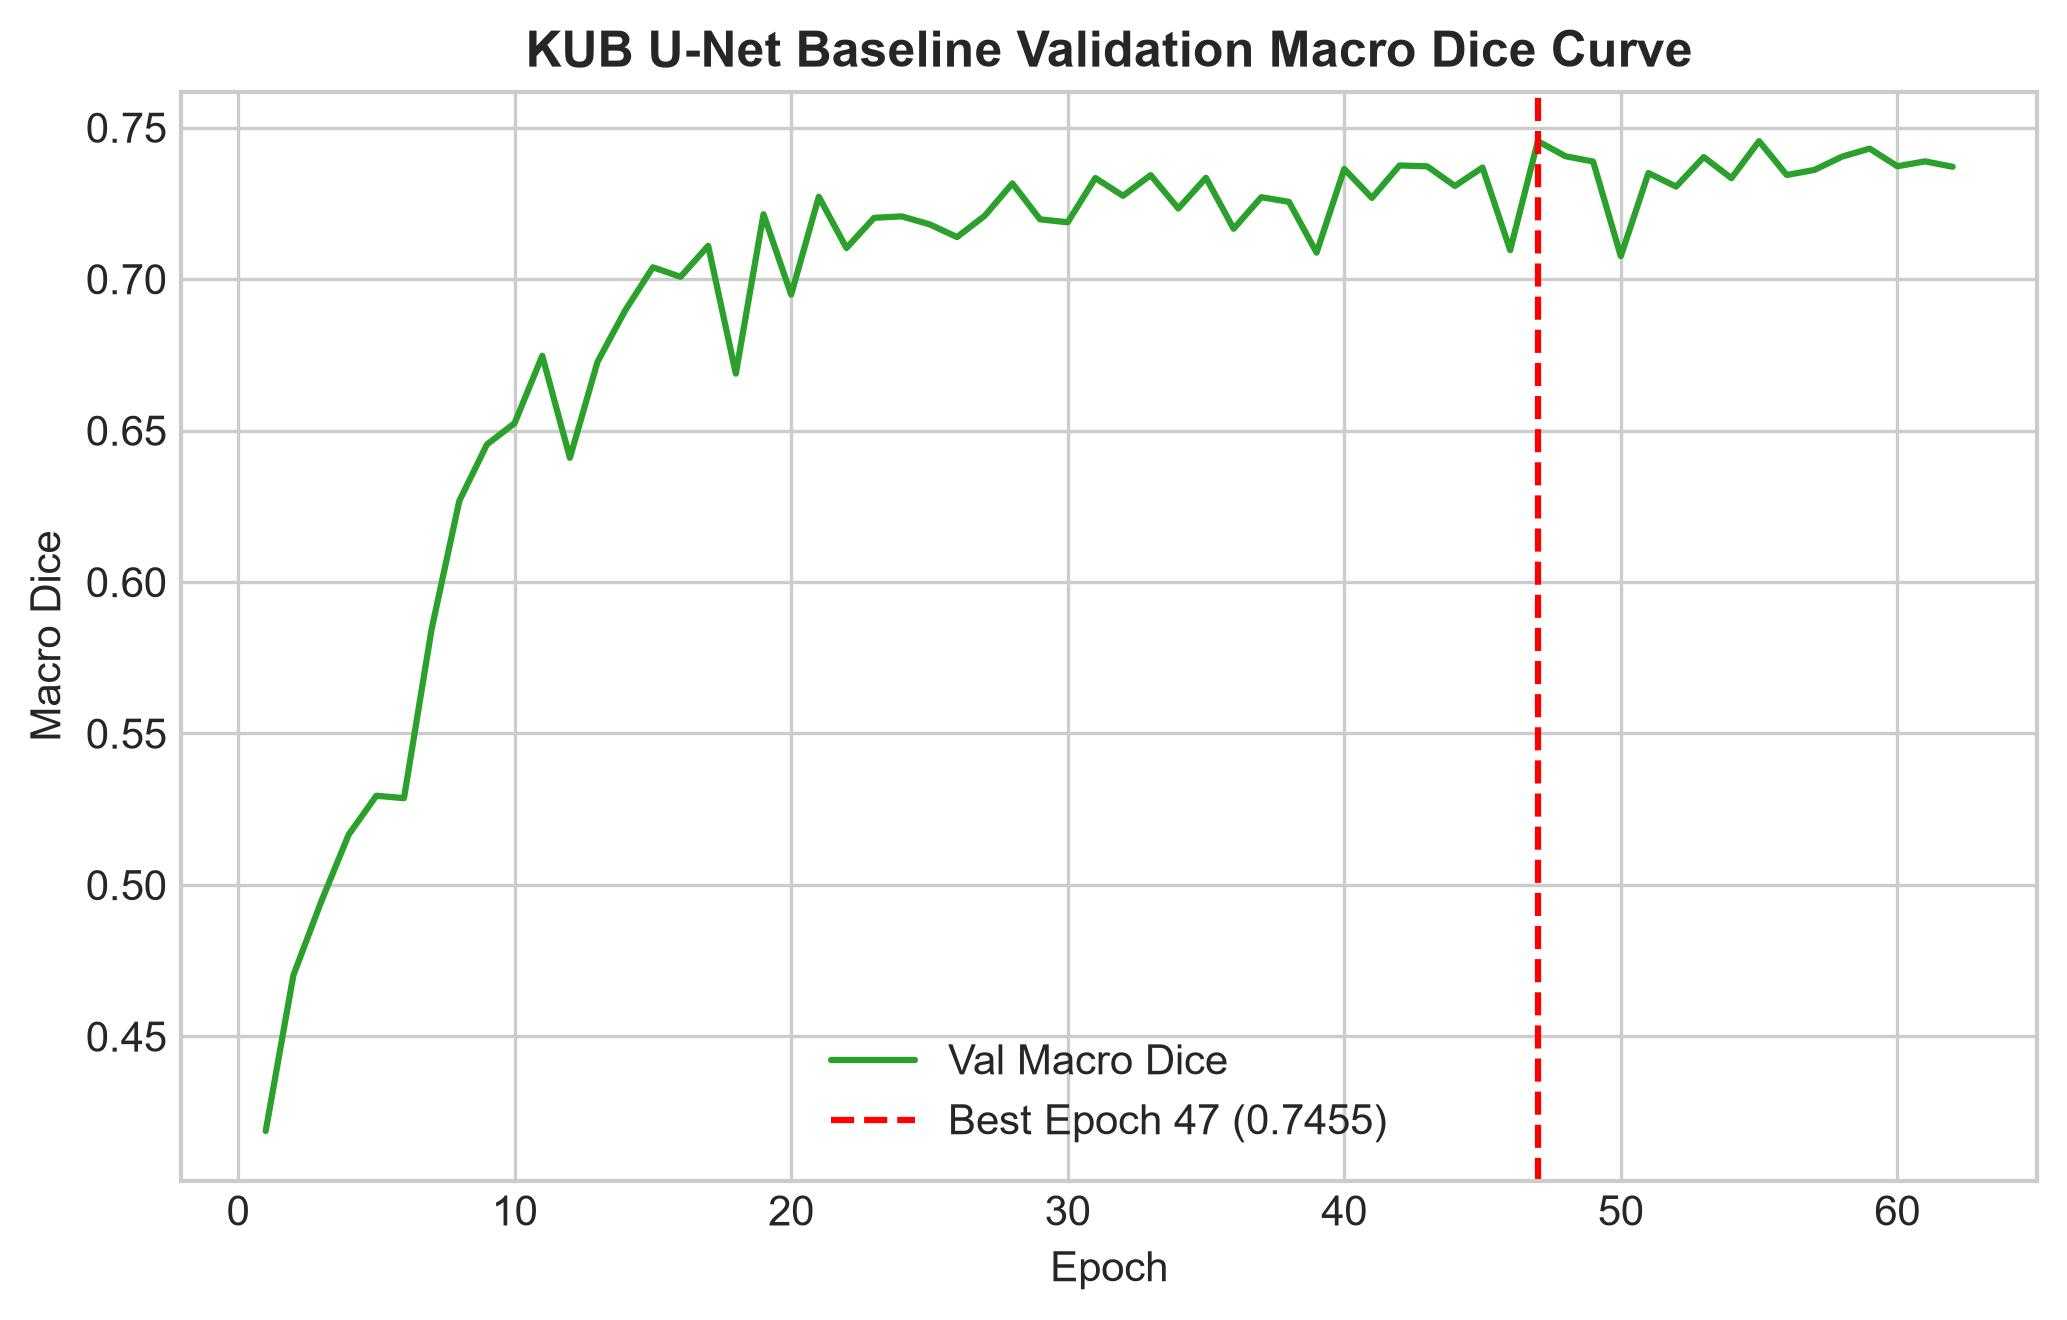

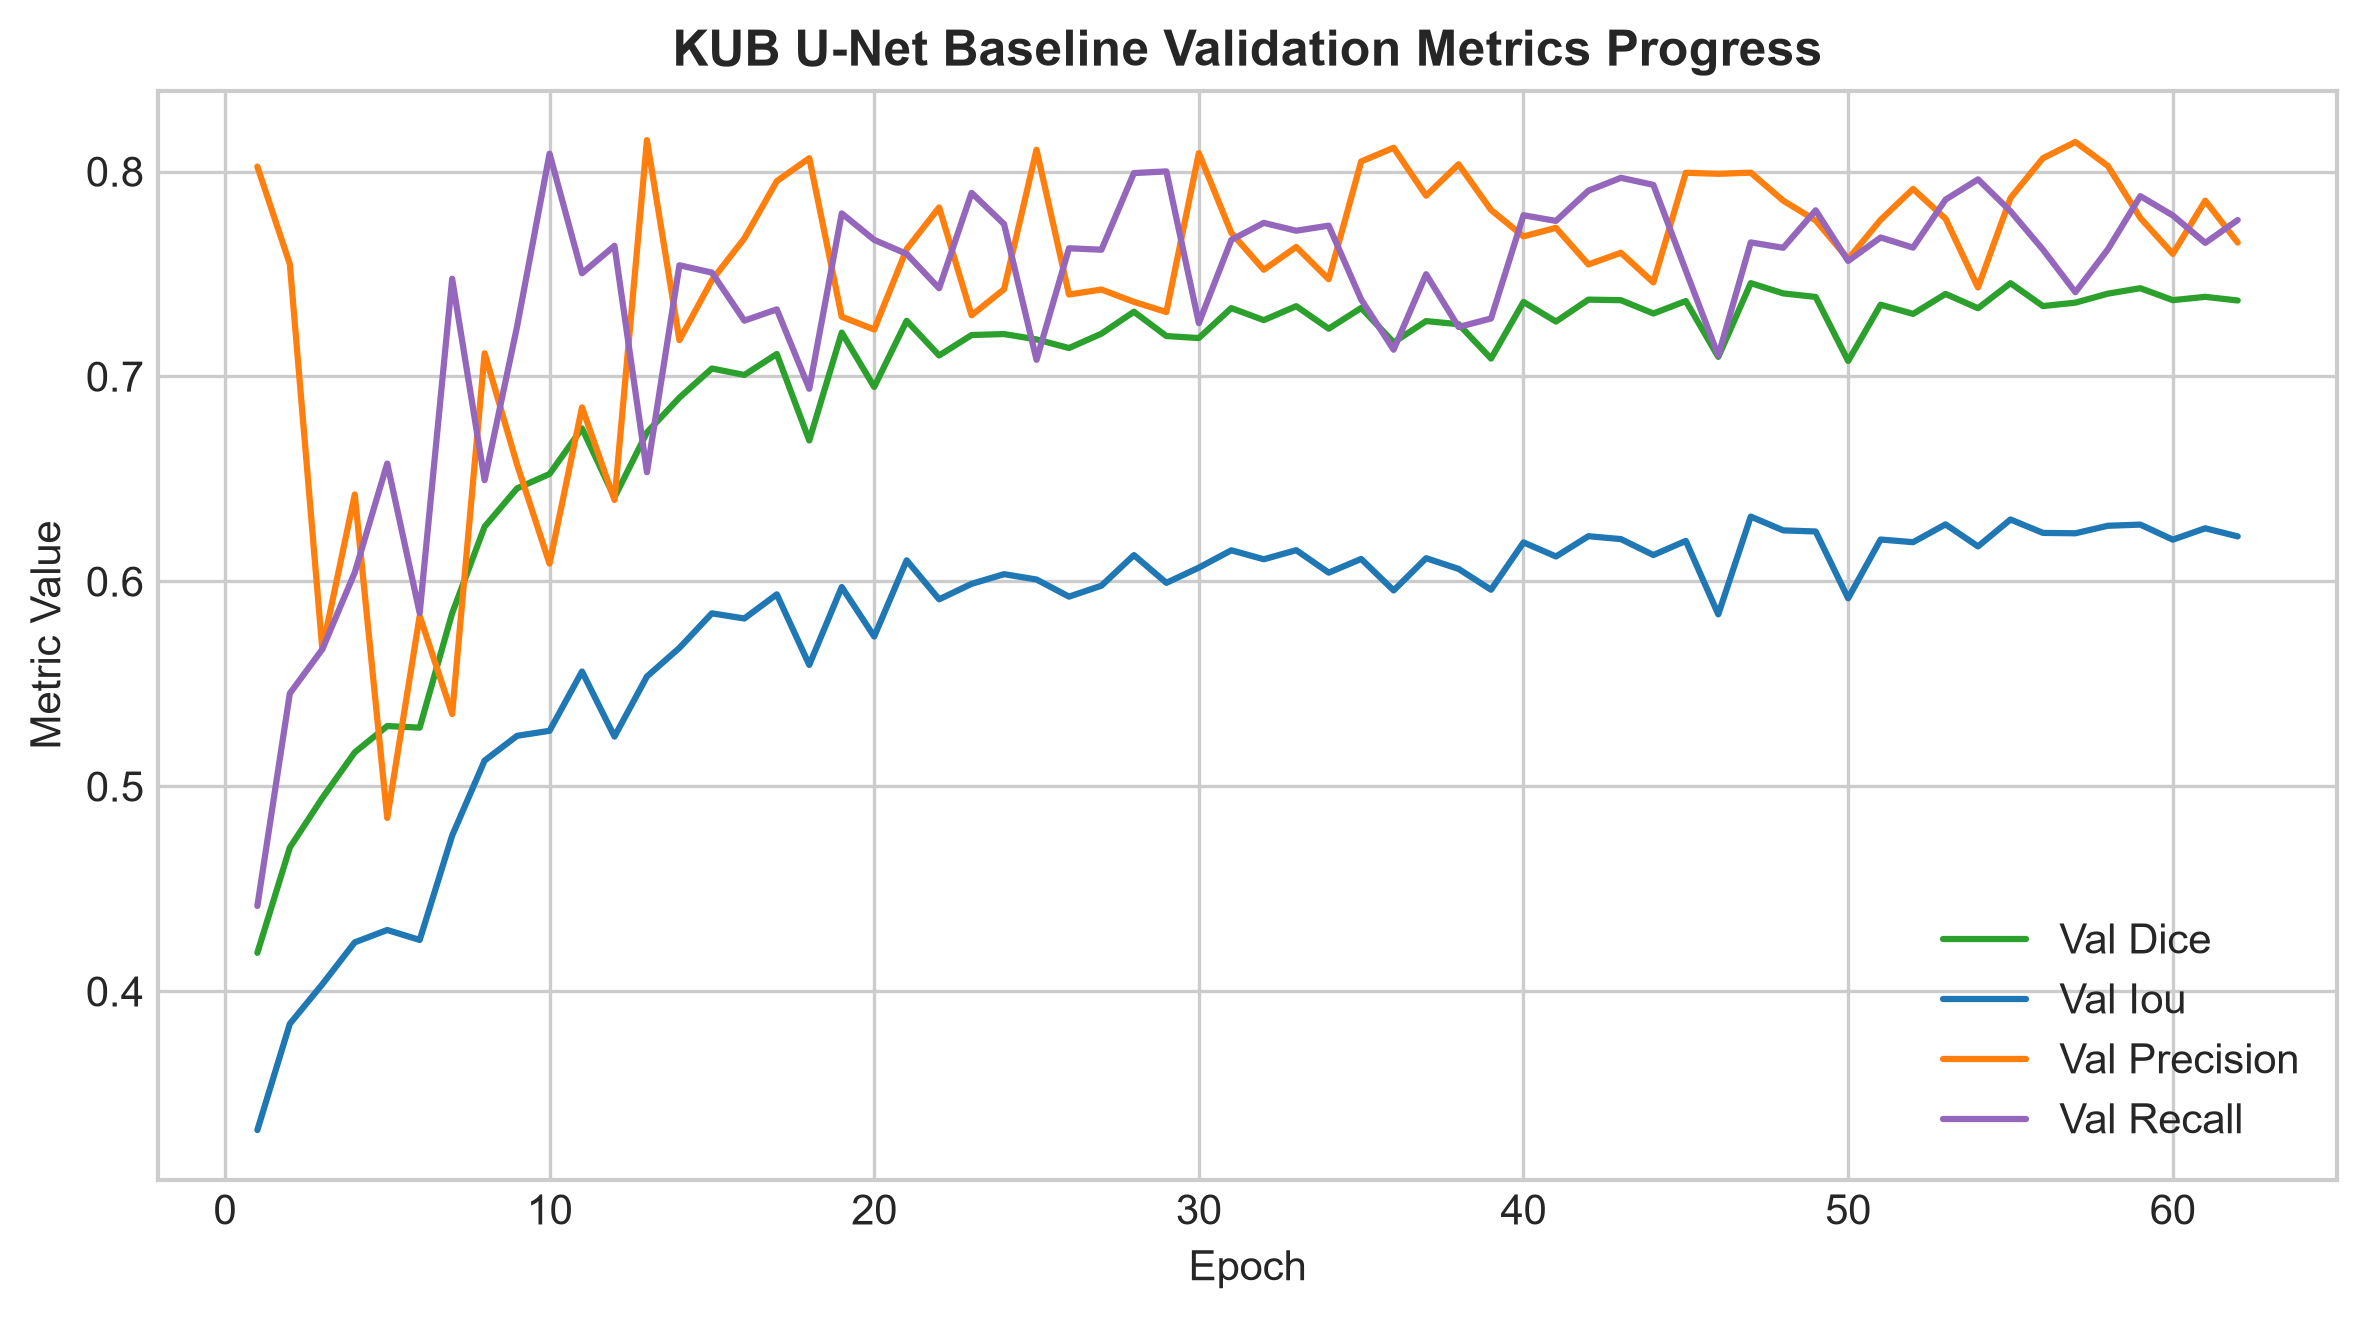

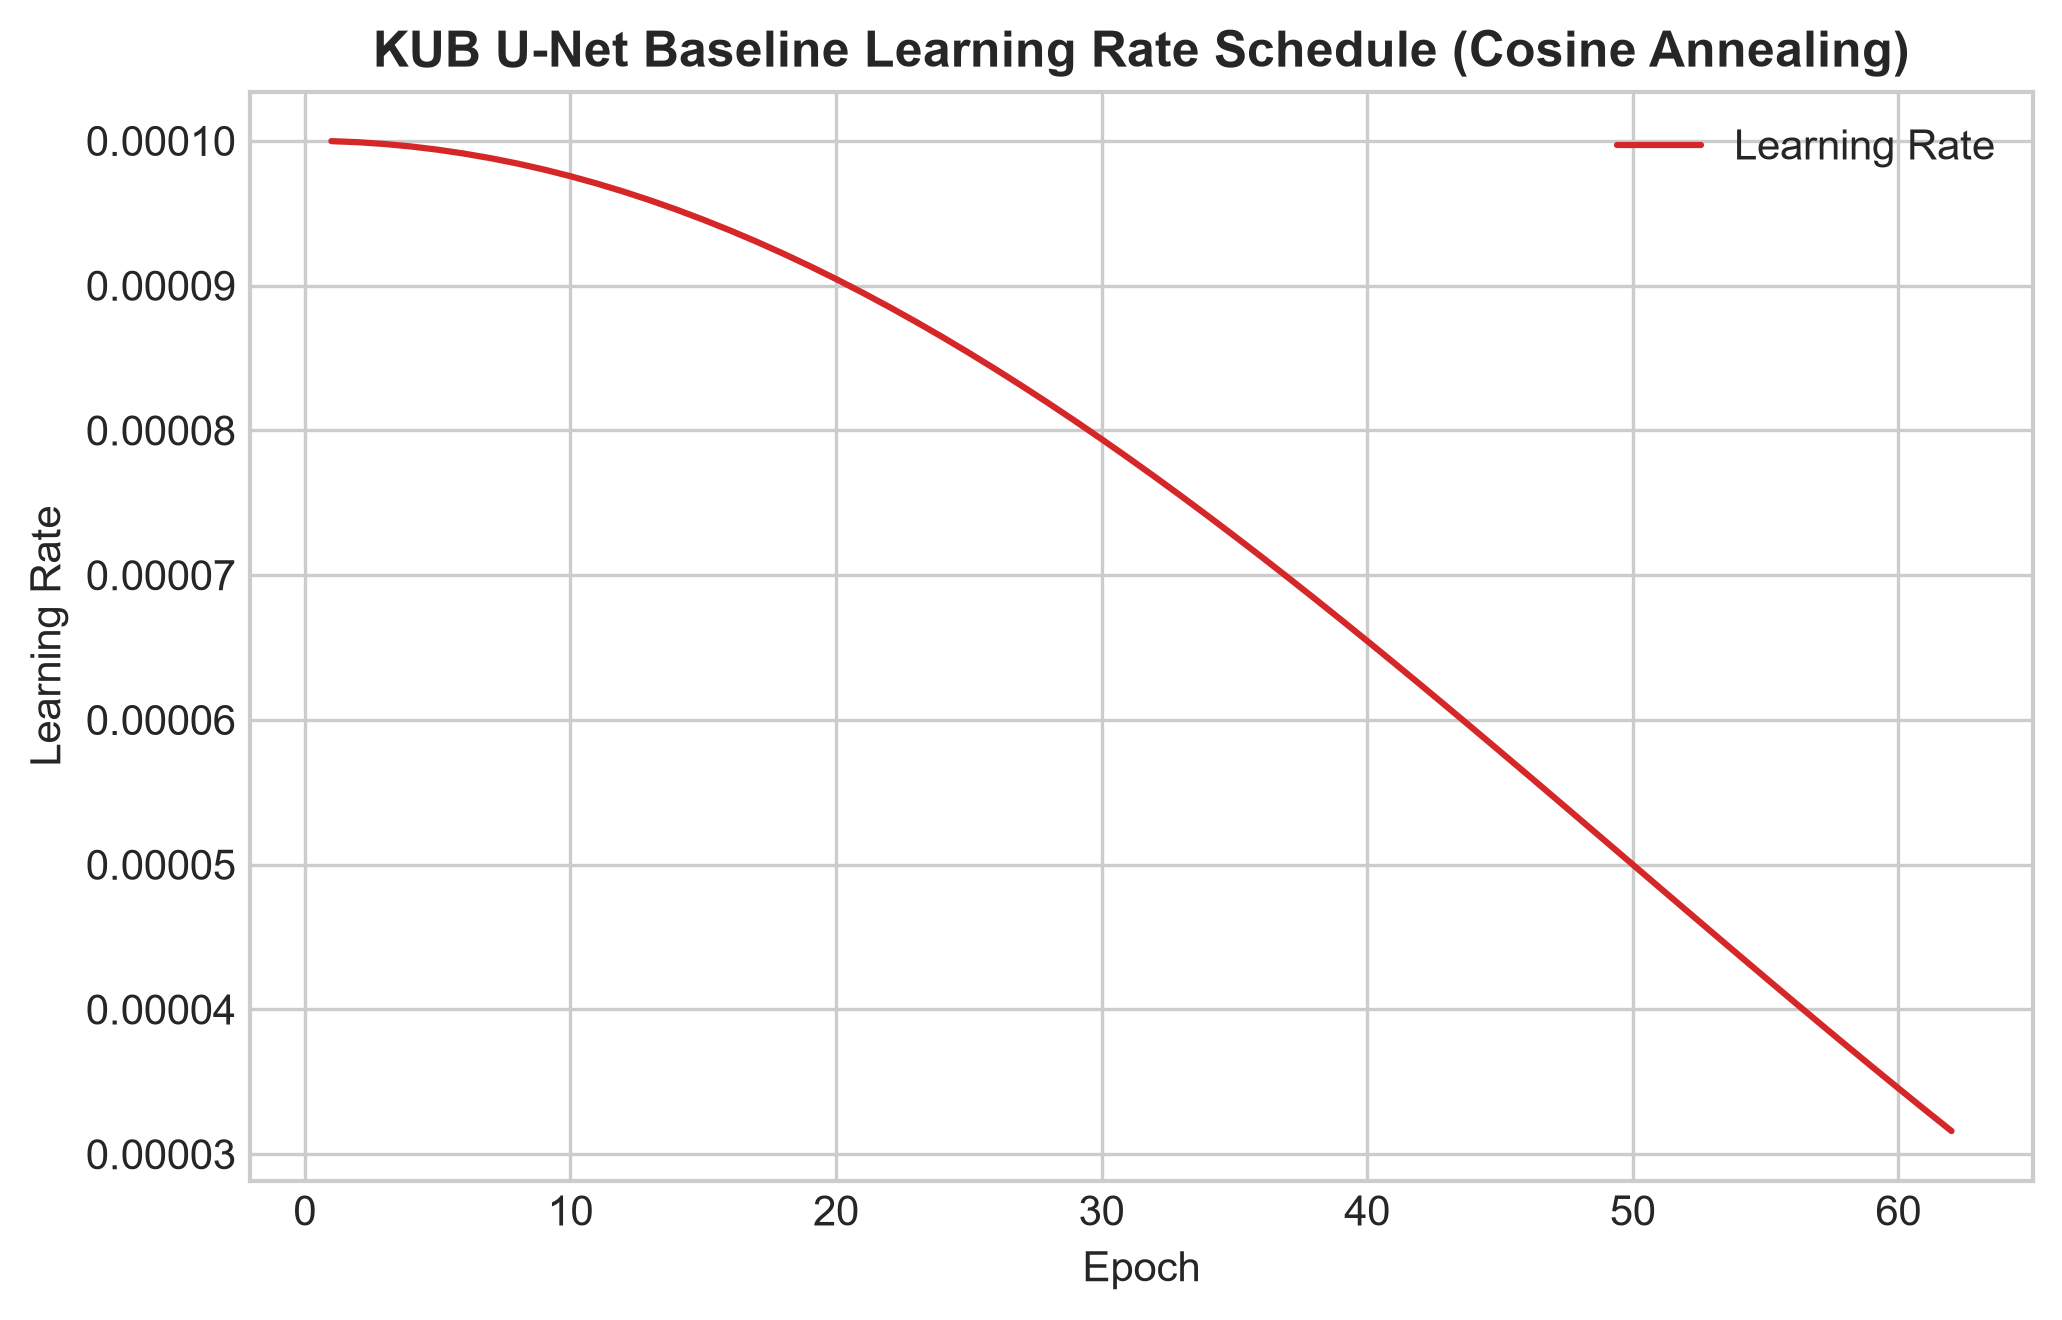

In [4]:
display(Image(filename=str(FIGURES / 'phase9_unet_loss_curves.png'), width=900))
display(Image(filename=str(FIGURES / 'phase9_unet_val_dice_curve.png'), width=900))
display(Image(filename=str(FIGURES / 'phase9_unet_metrics_curve.png'), width=900))
display(Image(filename=str(FIGURES / 'phase9_unet_lr_curve.png'), width=900))

## FOV and category results

,View_Type,N_Samples,Macro_Dice,Macro_IoU,Macro_Precision,Macro_Recall,Empty_Prediction_Rate,Object_Recall
0,FULL_FIELD,106,0.613015,0.498082,0.748744,0.639303,0.075472,0.80000
1,ROI_CROP,177,0.824911,0.711629,0.829810,0.840950,0.000000,0.99435


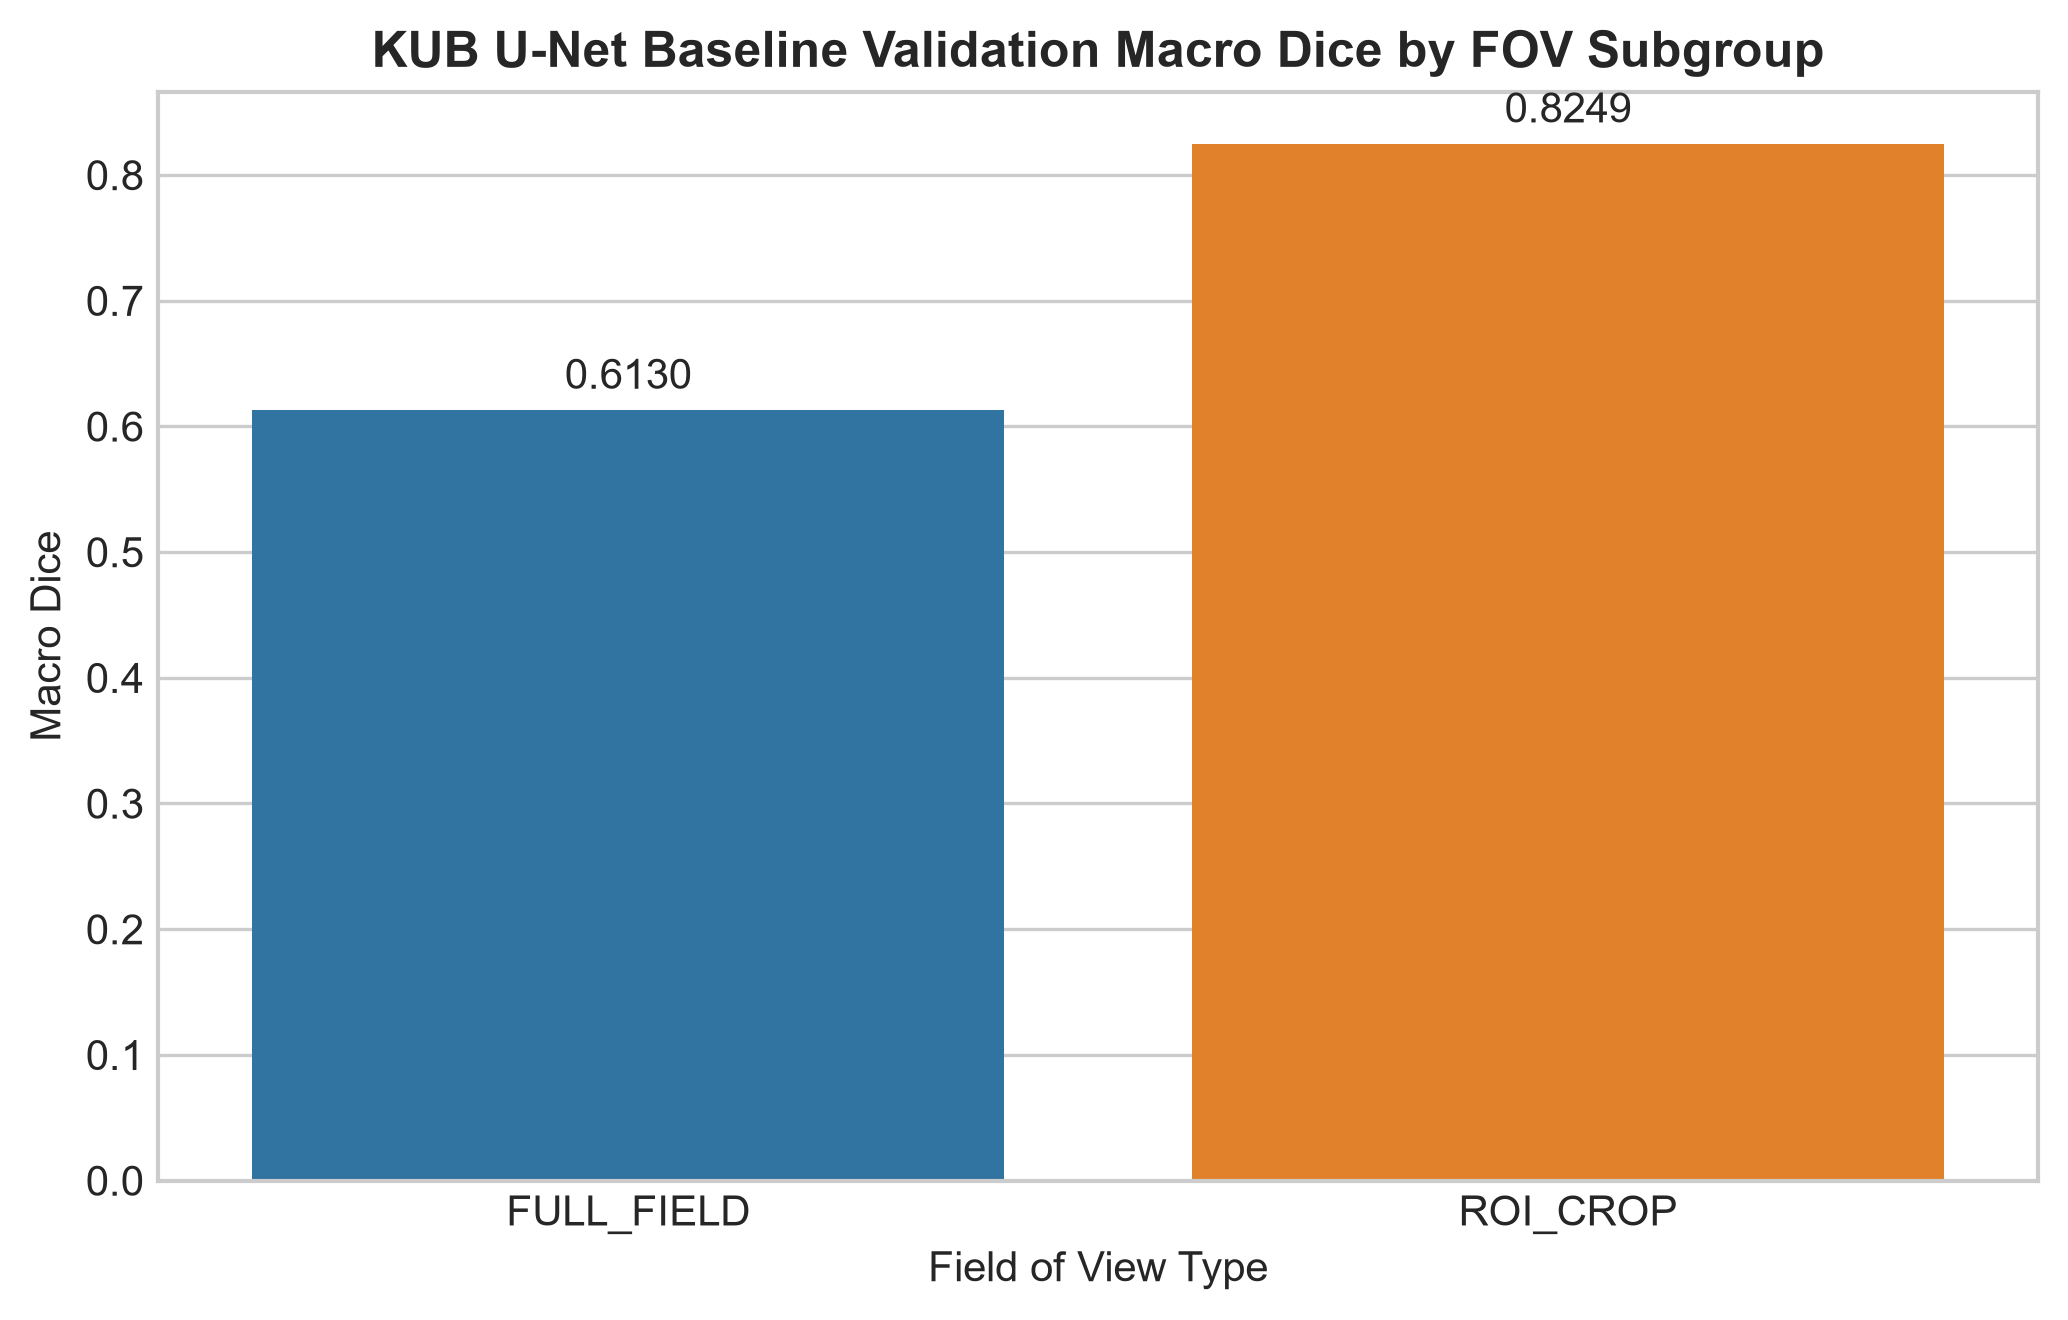

,Category,N_Samples,Macro_Dice,Macro_IoU,Macro_Precision,Macro_Recall,Empty_Prediction_Rate,Object_Recall
0,Bladder_Stone,145,0.723952,0.602283,0.764229,0.757936,0.020690,0.898810
1,Kidney_Stone,114,0.765935,0.661345,0.844077,0.762929,0.035088,0.919118
2,Ureteric_Stone,24,0.779140,0.667943,0.800221,0.822484,0.041667,0.857143


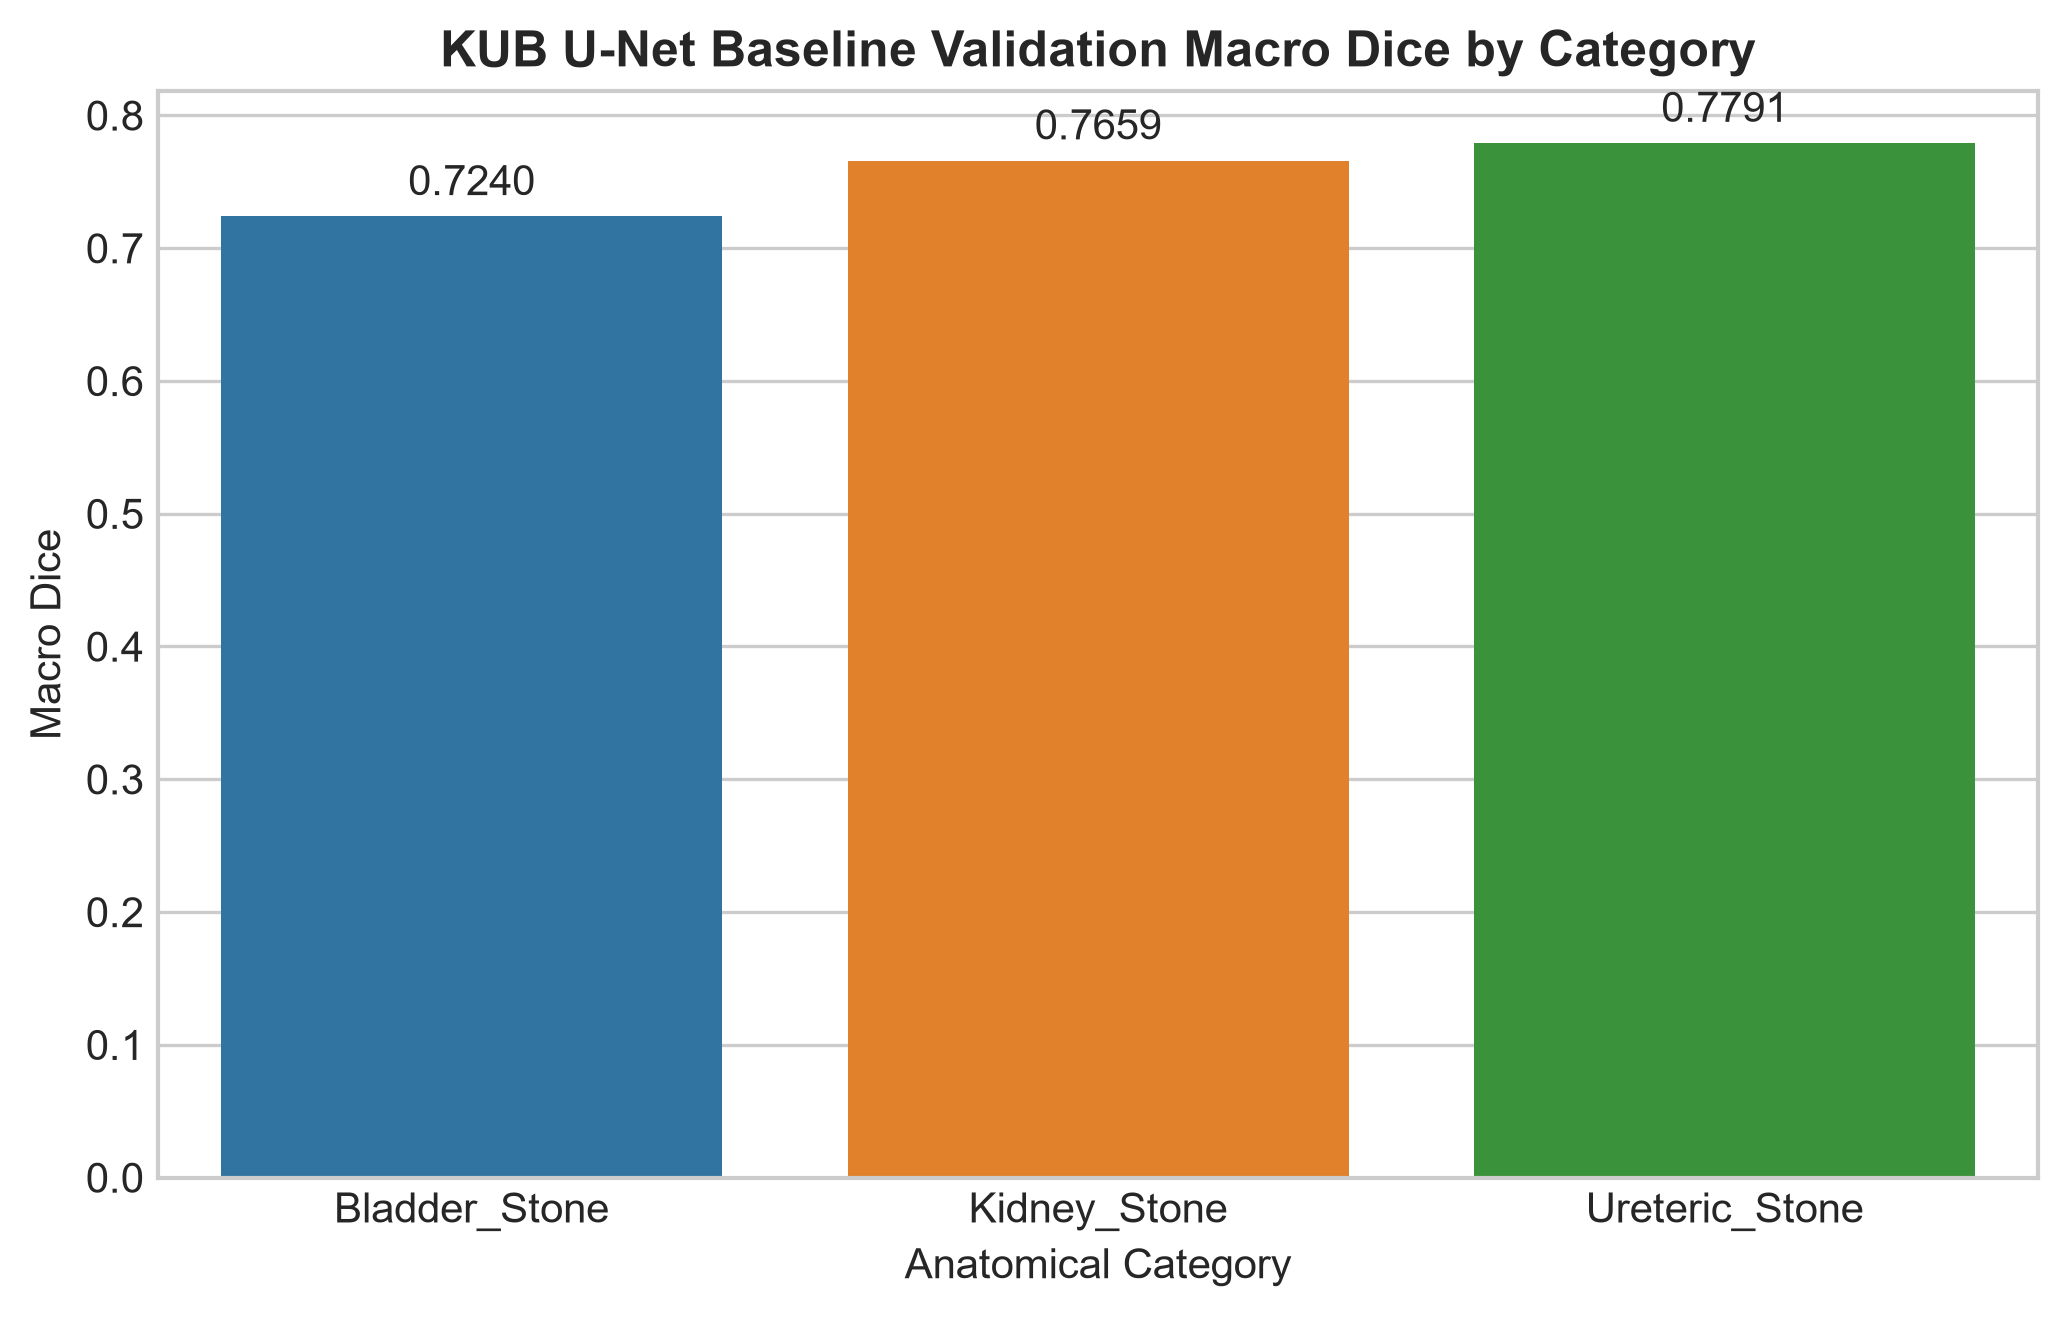

In [5]:
display(pd.read_csv(TABLES / 'phase9_unet_fov_summary.csv'))
display(Image(filename=str(FIGURES / 'phase9_unet_fov_performance.png'), width=900))
display(pd.read_csv(TABLES / 'phase9_unet_category_summary.csv'))
display(Image(filename=str(FIGURES / 'phase9_unet_category_performance.png'), width=900))

## Object-level and frozen size-stratum results

Size labels use `kub_size_v1`, whose thresholds were frozen from TRAIN FULL_FIELD components only. They are dataset-relative and are not clinical millimeter categories.

,Total_GT_Components,Total_Predicted_Components,Detected_GT_Components,Missed_GT_Components,Object_Recall,Missed_Object_Rate,False_Positive_Components
0,332,4842,300,32,0.903614,0.096386,2548


,Stratum,GT_Components,Detected_Components,Object_Recall
0,LARGE,18,17,0.944444
1,MEDIUM,36,29,0.805556
2,SMALL,29,24,0.827586
3,TINY,73,55,0.753425


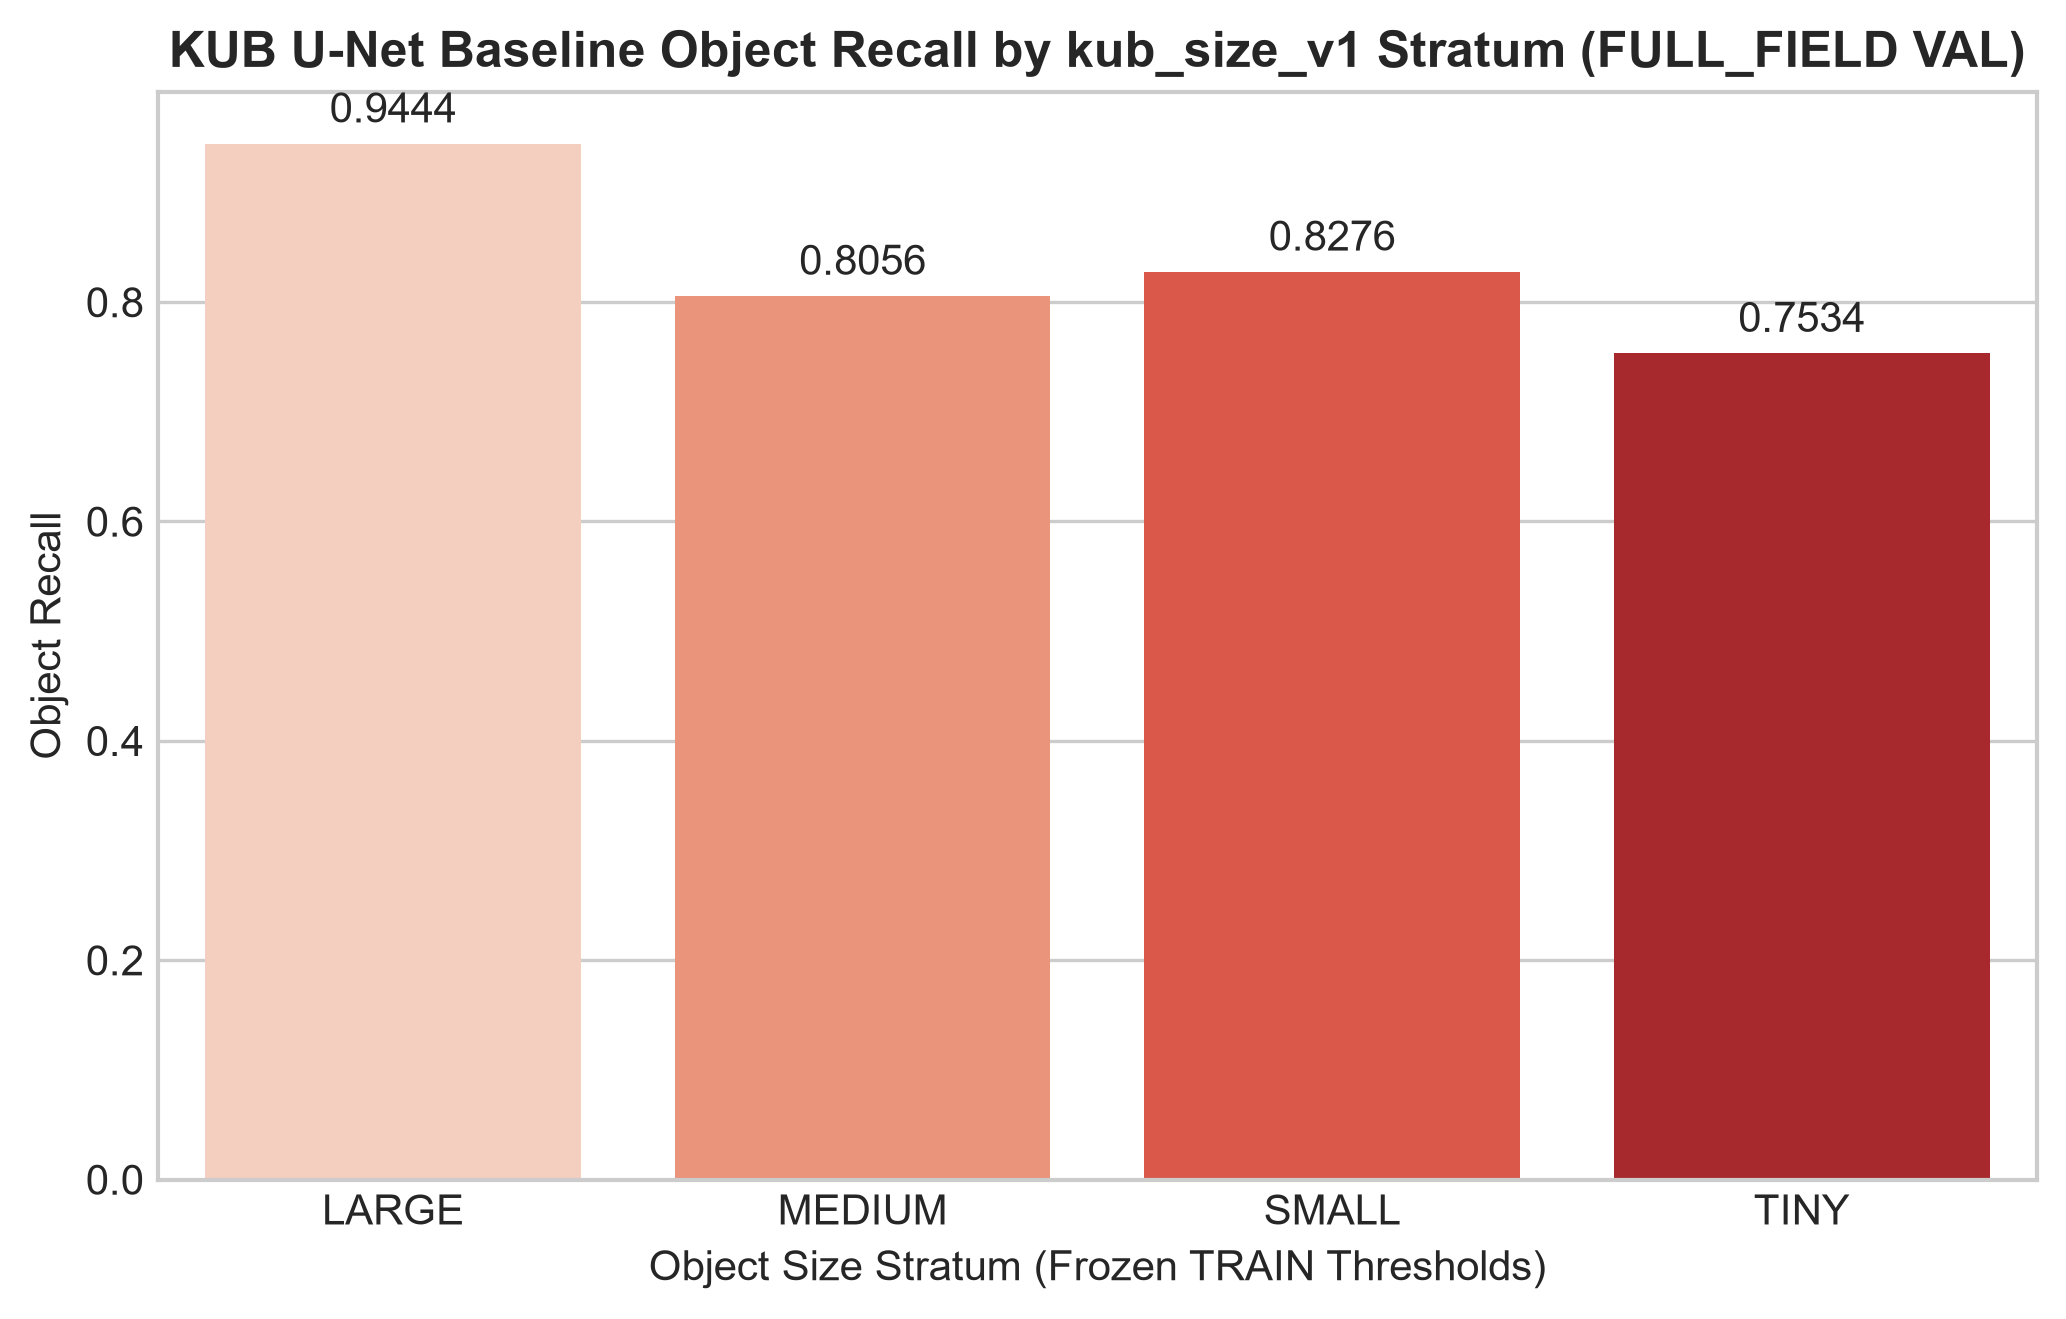

In [6]:
display(pd.read_csv(TABLES / 'phase9_unet_object_summary.csv'))
display(pd.read_csv(TABLES / 'phase9_unet_size_summary.csv'))
display(Image(filename=str(FIGURES / 'phase9_unet_size_object_recall.png'), width=900))

## FULL_FIELD single- versus multi-component analysis

Grouping uses the existing original-space `component_count` field: single-component means 1 and multi-component means >1. Object recall is pooled component recall from the existing per-component table; missed-object rate is its complement.

In [7]:
import numpy as np
per_image = pd.read_csv(TABLES / 'phase9_unet_val_per_image.csv')
per_component = pd.read_csv(TABLES / 'phase9_unet_val_per_component.csv')
ff = per_image[per_image['view_type'].eq('FULL_FIELD')].copy()
ff['Component_Group'] = np.where(ff['component_count'].gt(1), 'MULTI_COMPONENT', 'SINGLE_COMPONENT')
component_detection = per_component.groupby('sample_id')['detected'].agg(['sum', 'count'])
ff = ff.join(component_detection, on='sample_id')
multi_summary = ff.groupby('Component_Group').agg(
    N=('sample_id', 'size'), Macro_Dice=('dice', 'mean'),
    GT_Components=('count', 'sum'), Detected_Components=('sum', 'sum'))
multi_summary['Object_Recall'] = multi_summary['Detected_Components'] / multi_summary['GT_Components']
multi_summary['Missed_Object_Rate'] = 1 - multi_summary['Object_Recall']
display(multi_summary.reset_index())

,Component_Group,N,Macro_Dice,GT_Components,Detected_Components,Object_Recall,Missed_Object_Rate
0,MULTI_COMPONENT,50,0.620885,100,79,0.790000,0.210000
1,SINGLE_COMPONENT,56,0.605989,56,46,0.821429,0.178571


## Deterministic qualitative examples — R3 traceability labels

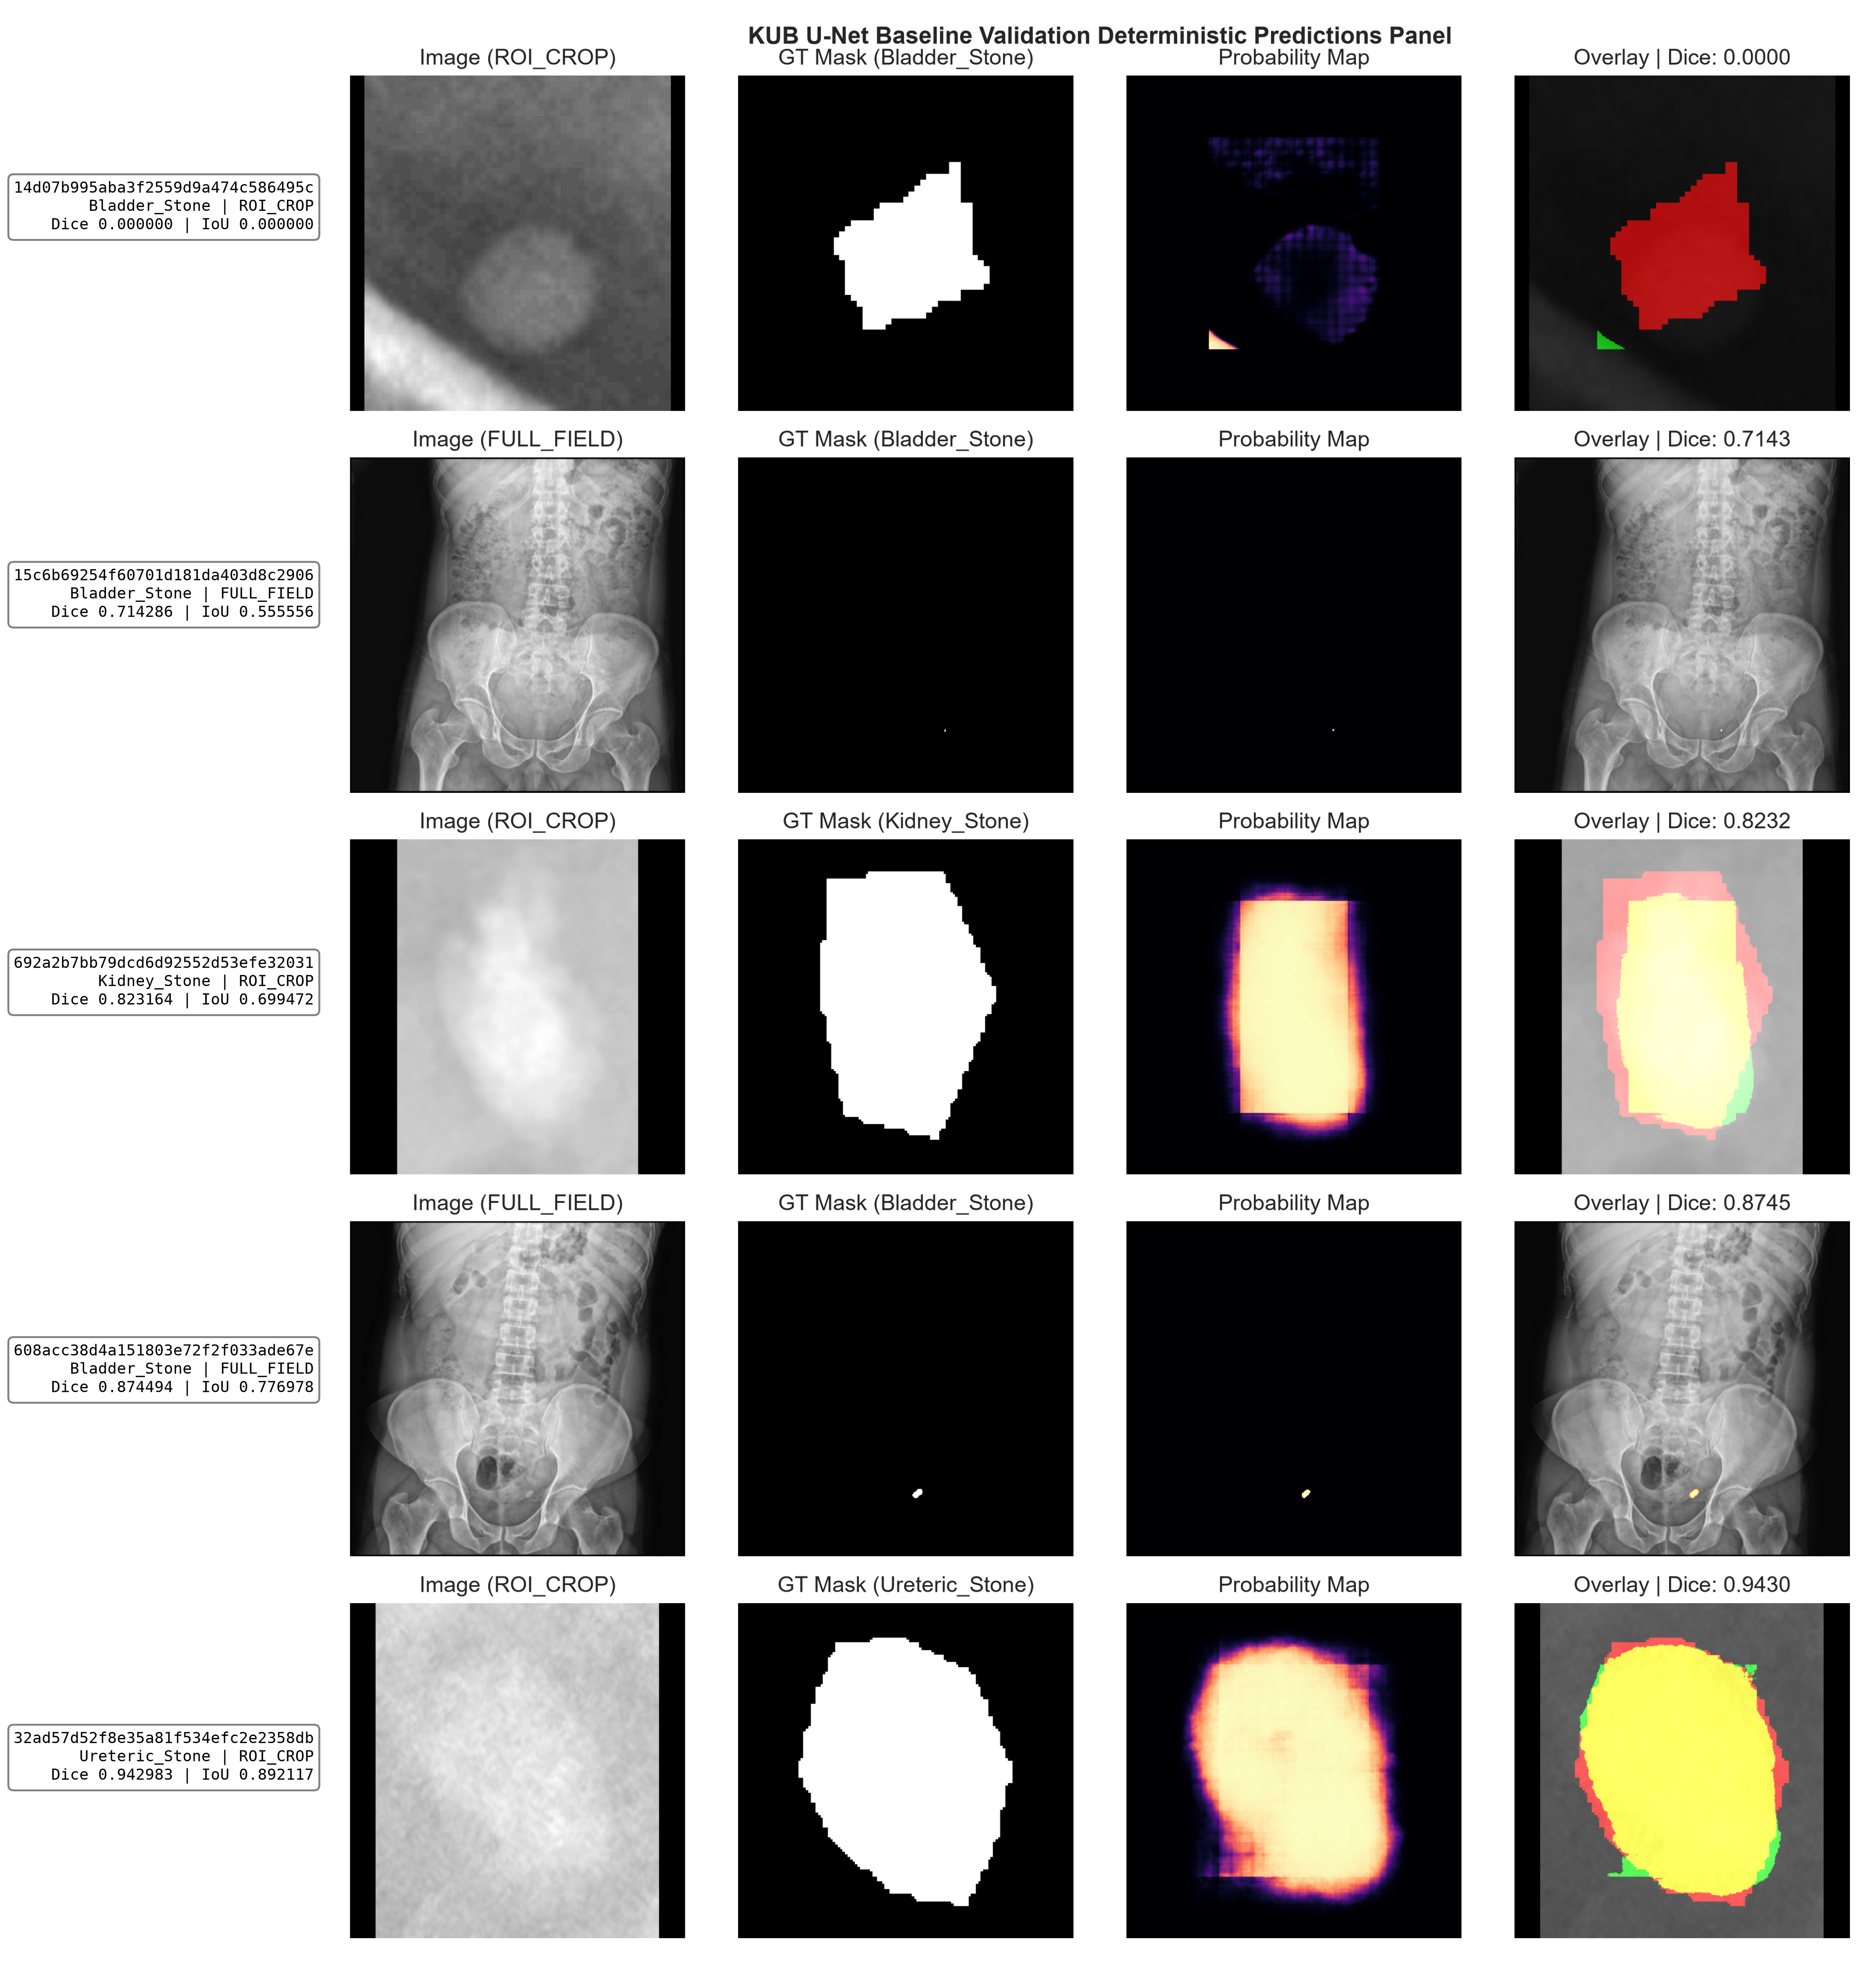

In [8]:
display(Image(filename=str(QUAL / 'phase9_val_qualitative_panel_r3.png'), width=1200))

## Deterministic failure panel — R3 traceability labels

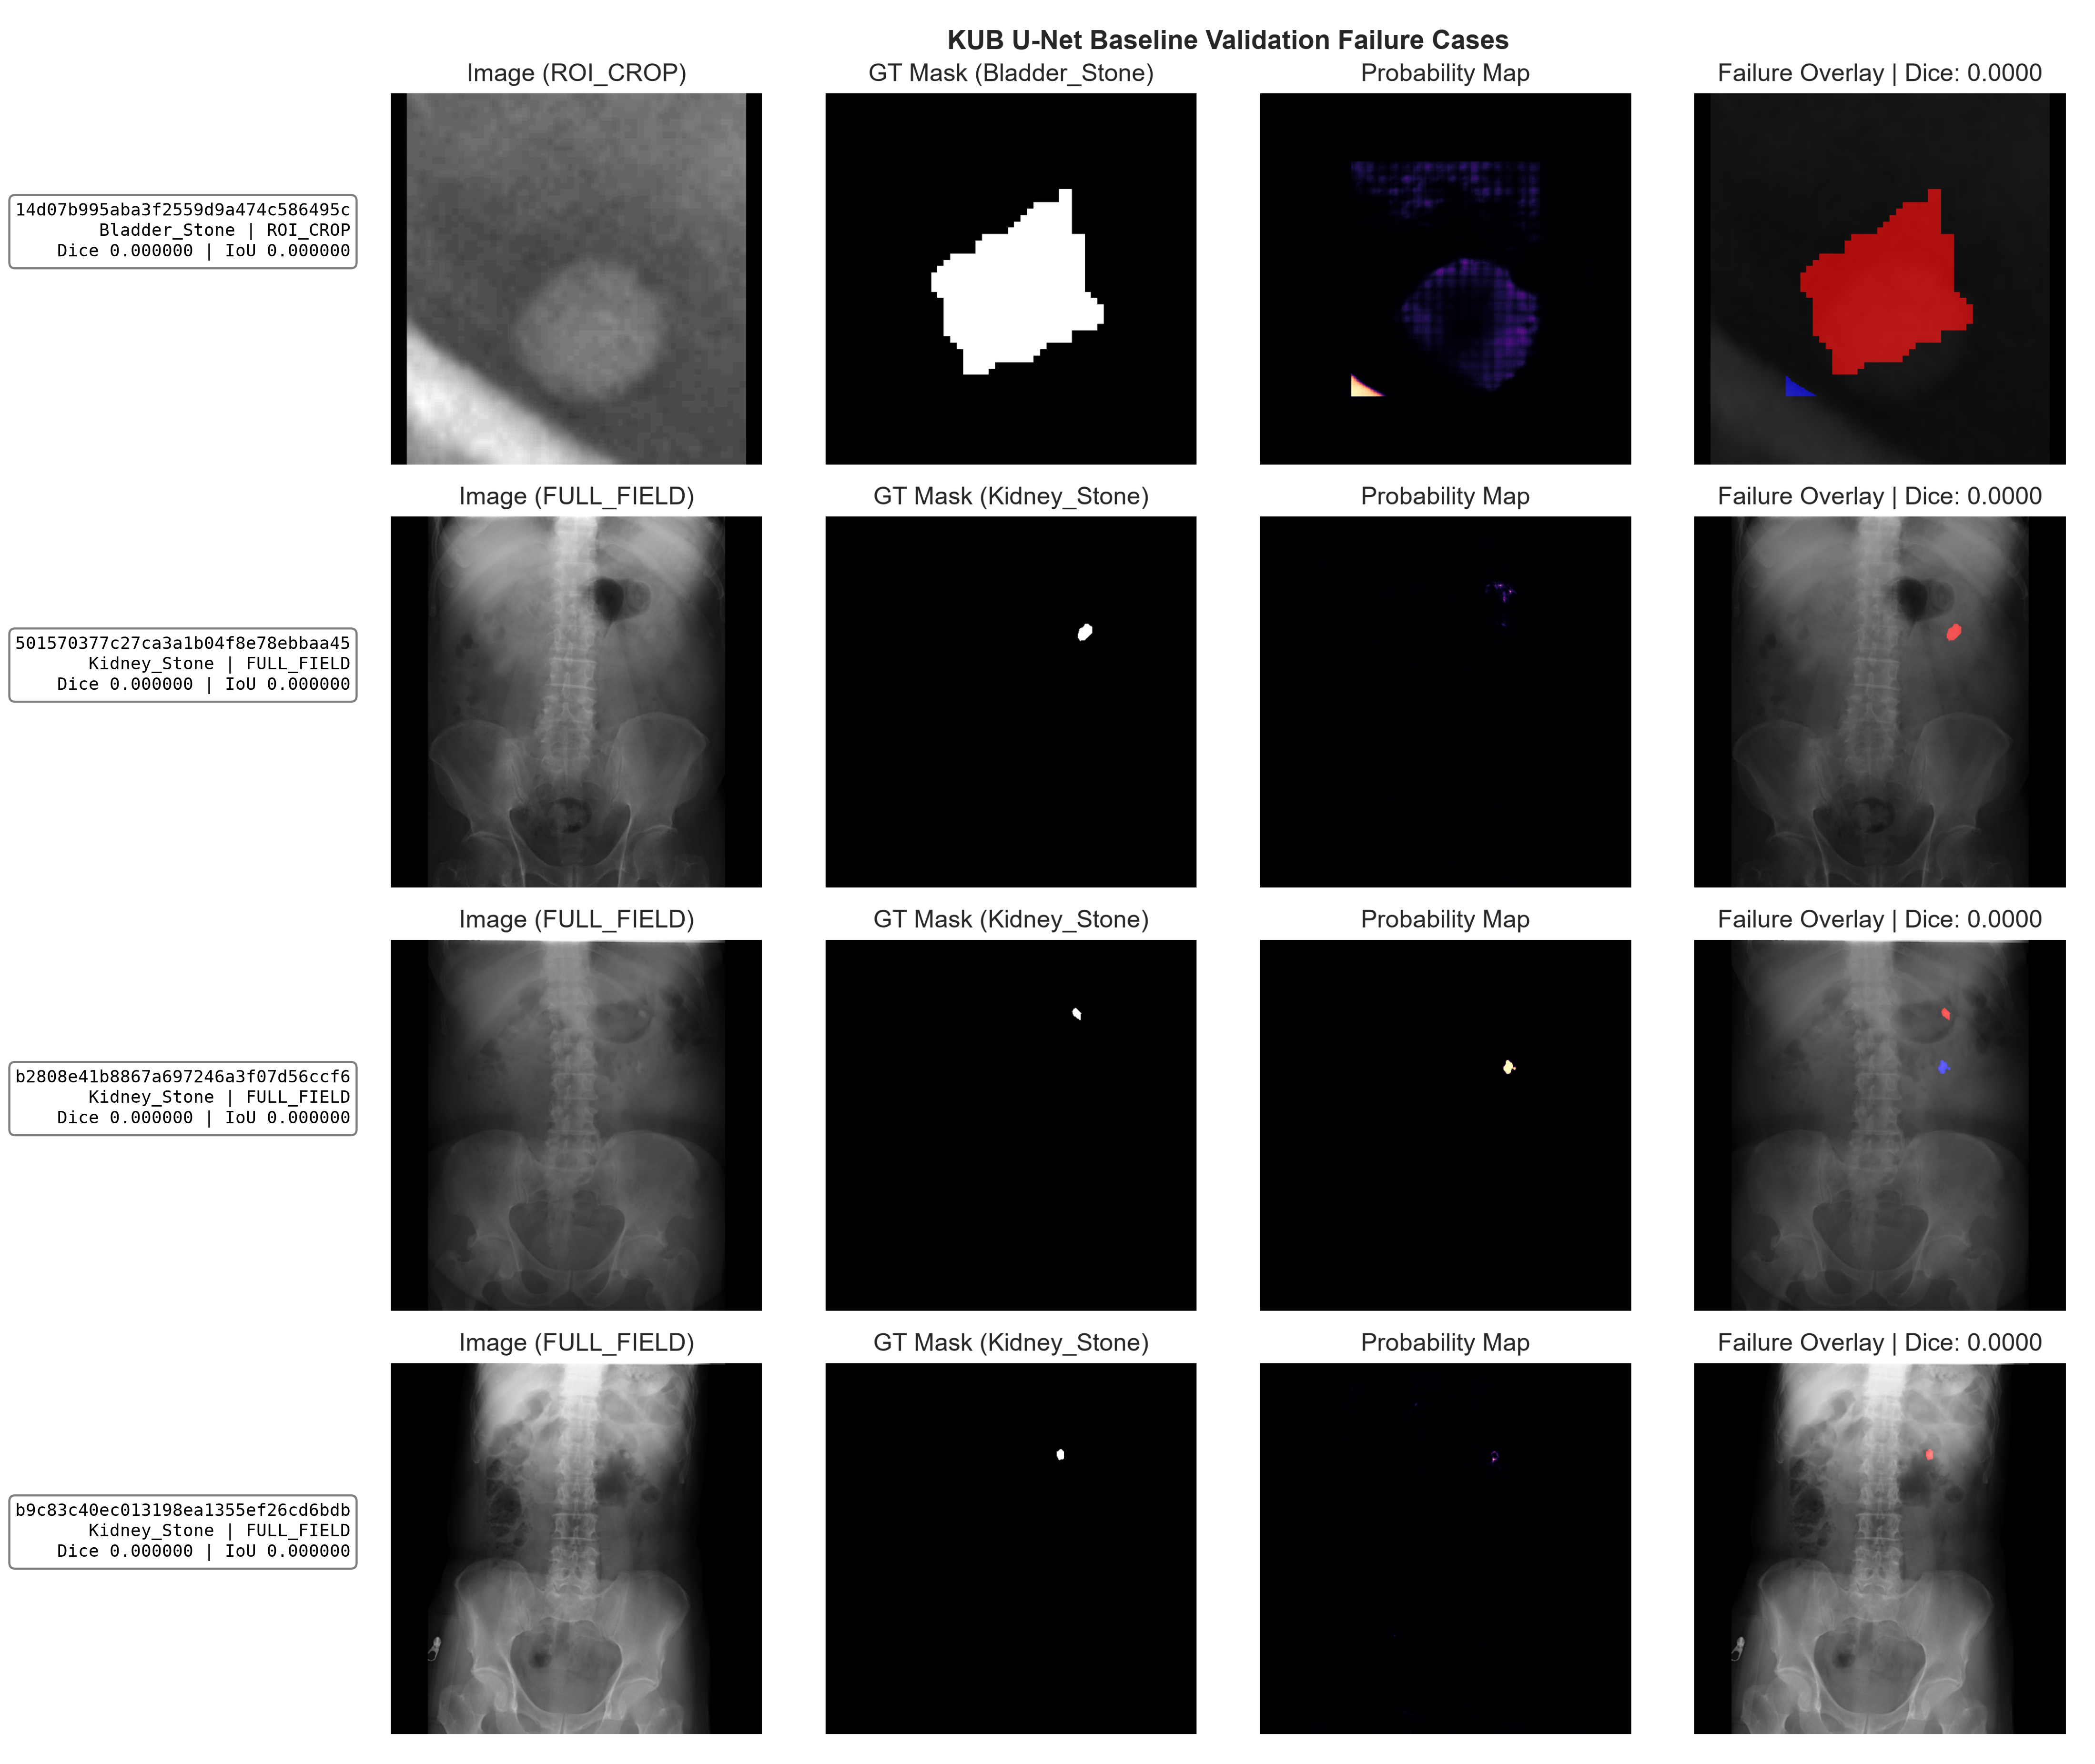

In [9]:
display(Image(filename=str(QUAL / 'phase9_val_failure_panel_r3.png'), width=1200))

## HD95 validity and provenance

HD95 was valid for **275** images and invalid for **8** images. All invalid cases were empty predictions and are recorded as invalid/NaN rather than assigned a fabricated distance.

Authoritative source tables are retained under `reports/tables/`; checkpoint and result hashes are recorded in `reports/audits/phase9_kub_unet_baseline.json`. No TEST metrics are present.

In [10]:
display(per_image.groupby(['hd95_valid','hd95_invalid_reason'], dropna=False).size().rename('N').reset_index())
original_rows = per_component.groupby('sample_id').size()
row_audit = per_image[['sample_id','view_type','component_count','gt_component_count']].copy()
row_audit['original_component_rows'] = row_audit['sample_id'].map(original_rows).fillna(0).astype(int)
display(row_audit[row_audit['original_component_rows'] != row_audit['gt_component_count']])
print(f'Per-image rows: {len(per_image)}; original-space per-component rows: {len(per_component)}')

,hd95_valid,hd95_invalid_reason,N
0,False,empty_prediction,8
1,True,NaN,275


,sample_id,view_type,component_count,gt_component_count,original_component_rows
8,32c06da36a7221dc5369e3ee4723c10c,FULL_FIELD,2,1,2


Per-image rows: 283; original-space per-component rows: 333


### Why the component CSV has 333 rows while the object summary has 332 components

The schemas count components at different stages. `phase9_unet_val_per_component.csv` has one row for each **original-space GT component** from the retained component metadata (333 rows). The object summary labels the binary GT masks **after** aspect-ratio resize and padding at 512×512 (332 components). For sample `32c06da36a7221dc5369e3ee4723c10c`, two original FULL_FIELD components (1,145 and 1,047 pixels) become touching and merge into one connected component after nearest-neighbor downsampling. Thus the one-row difference is expected, traceable preprocessing behavior—not a prediction-only or spurious row. Original-component recall and preprocessed-mask object totals remain scientifically consistent within their explicitly documented schemas.

## Phase control

**Phase 9 complete. STOP. Phase 10 was not executed and requires explicit researcher authorization.**